# Real-footprint corpus review and acceptance

Review a small deterministic cross-municipality sample and make geometry acceptance part of the diversity report.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

This notebook is a review of **source diversity and preparation decisions**, not a miniature national dataset. Sorted fixture selection gives a repeatable six-record sample across three municipality codes. The polygons can be complex even when their number is small.

The acceptance table is as important as the gallery. `GeometrySpec.from_footprint(...)` receives only accepted cleaned outlines and explicitly assumed heights. In the workflow diagram, this stays in the describe-and-inspect stage: no weather, assembly or operational evidence has been attached yet.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Select a documented corpus sample

Select the first two fixture files per municipality in sorted order. This makes the sample reproducible but not statistically representative. The source fixture describes whether the outline is a roof-edge proxy.

### Read the code and output

The municipality prefix and source stratum describe where each fixture came from and how it was selected for testing. They do not provide population weights. A roof-edge proxy may differ from the facade outline used in an energy model; record that interpretation instead of silently treating both as identical observations.

Reference: [Exposure changes above an adjoining lower wing](../../docs/figures/geometry-height-exposure.svg). This linked documentation illustration is separate from the outputs computed below.

In [2]:
from shapely.geometry import shape
from shapely.affinity import translate
sample=[]
for municipality in ["0181","1480","2584"]:
    for path in sorted((ROOT/"tests/fixtures/footprints").glob(municipality+"-*.json"))[:2]:
        payload=json.loads(path.read_text())
        sample.append((path,payload))
table([{ "fixture":p.name,"municipality":d["municipality"],"stratum":d["selection_stratum"],"outline":d["insamlingslage"]} for p,d in sample])

,fixture,municipality,stratum,outline
0,0181-000338b8-c89a-45e2-93f5-f697c11fa8dc.json,0181,complex,Takkant
1,0181-016edab7-be03-40dd-ba56-7fcd2c93ed14.json,0181,complex,Takkant
2,1480-00bba425-2877-497b-a764-898ae346a9fe.json,1480,holes,Takkant
3,1480-0324d609-2e98-48bb-bf31-18d846cbb889.json,1480,holes,Takkant
4,2584-05fd421d-6804-47e2-a559-cd27edbf4256.json,2584,general,Takkant
5,2584-061e6e3e-fcdd-49d6-8c76-da8b393cebf1.json,2584,general,Takkant


,fixture,municipality,stratum,outline
0,0181-000338b8-c89a-45e2-93f5-f697c11fa8dc.json,0181,complex,Takkant
1,0181-016edab7-be03-40dd-ba56-7fcd2c93ed14.json,0181,complex,Takkant
2,1480-00bba425-2877-497b-a764-898ae346a9fe.json,1480,holes,Takkant
3,1480-0324d609-2e98-48bb-bf31-18d846cbb889.json,1480,holes,Takkant
4,2584-05fd421d-6804-47e2-a559-cd27edbf4256.json,2584,general,Takkant
5,2584-061e6e3e-fcdd-49d6-8c76-da8b393cebf1.json,2584,general,Takkant


## Review preparation without hiding failures

Run preparation on the source metric polygons. Display each shape in its own local plotting frame, preserving dimensions. Only accepted preparations are used for extrusion.

### Read the code and output

Translation is used only for the gallery, bringing each outline near its own plotting origin while preserving its dimensions. The geometries passed to EPSM retain their supplied coordinates and CRS metadata. Count accepted, review and rejected cases over all six source records before focusing on a successful preview.

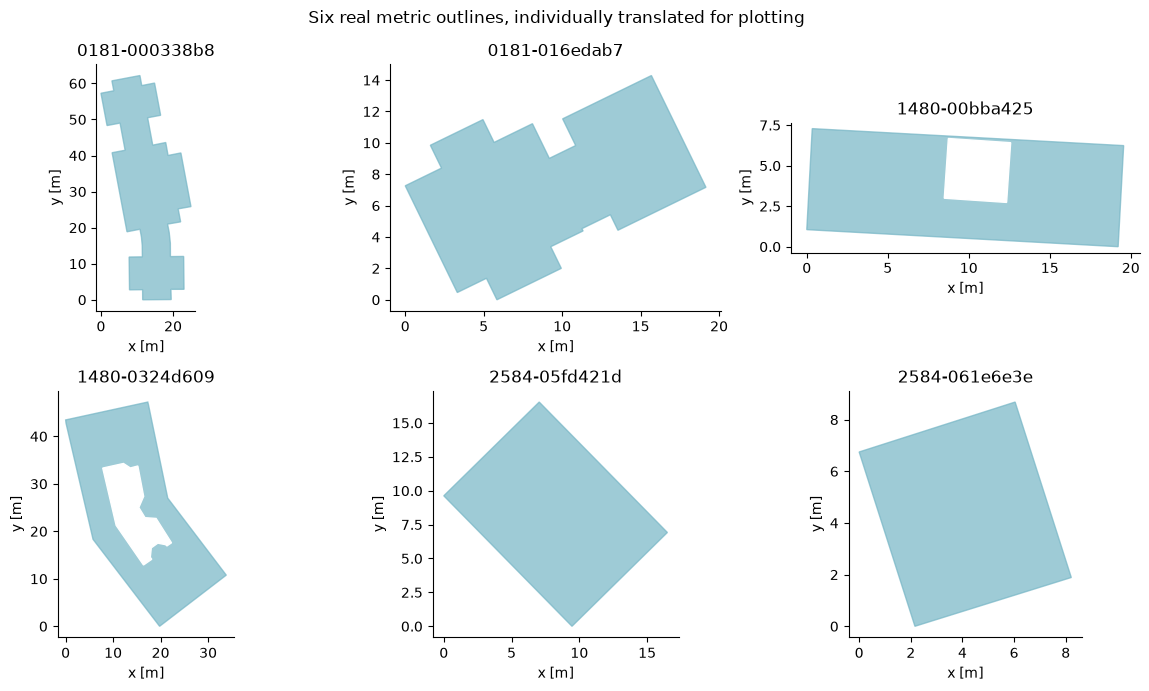

,fixture,status,area_m2,reasons
0,0181-000338b8-c89a-45e2-93f5-f697c11fa8dc.json,accepted,836.740276,()
1,0181-016edab7-be03-40dd-ba56-7fcd2c93ed14.json,accepted,140.239560,()
2,1480-00bba425-2877-497b-a764-898ae346a9fe.json,accepted,106.004314,()
3,1480-0324d609-2e98-48bb-bf31-18d846cbb889.json,accepted,653.161389,()
4,2584-05fd421d-6804-47e2-a559-cd27edbf4256.json,accepted,133.128118,()
5,2584-061e6e3e-fcdd-49d6-8c76-da8b393cebf1.json,accepted,45.082944,()


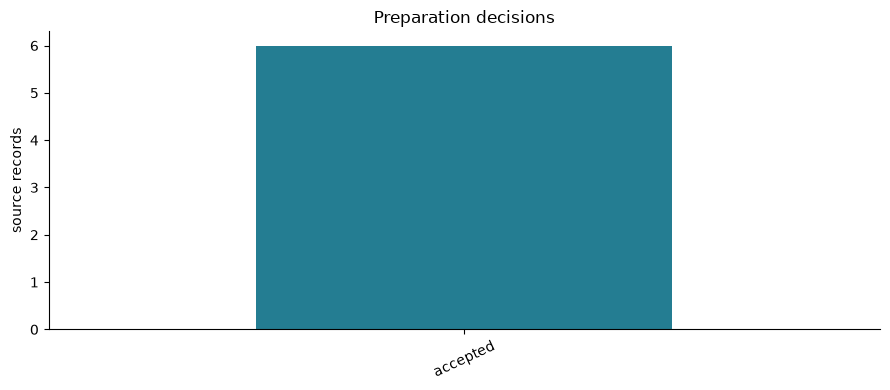

In [3]:
rows=[]; gallery={}; accepted=[]
for path,data in sample:
    raw=shape(data["source_geometry"])
    result=prepare_geometry(raw,GeometryPolicy())
    rows.append({"fixture":path.name,
                 "status":result.status,
                 "area_m2":raw.area,
                 "reasons":str(result.reasons)})
    x,y,_,_=raw.bounds

    gallery[path.stem[:13]]=translate(raw,xoff=-x,yoff=-y)

    if result.status=="accepted":
        accepted.append(GeometrySpec.from_footprint(result.cleaned_geometry,
                                                    storeys=3,
                                                    storey_height_m=3,
                                                    source_crs="EPSG:3006",
                                                    height_status="assumed",
                                                    outline_kind="roof_edge_proxy",
                                                    outline_reviewed=False))

plans(gallery,"Six real metric outlines, individually translated for plotting")
frame=table(rows)
bars(frame.status.value_counts().to_dict(),"source records","Preparation decisions")
assert len(rows)==6

## Inspect one accepted shape

The three storeys are an explicit teaching assumption. An accepted planar outline does not validate height, facade offset or energy inputs.

### Read the code and output

The synthetic L-shape at the end is a **separate controlled-reference example** for `scaled_to_area(600)`. It answers how to compare forms at equal area; it neither repairs nor approximates the real outline shown above. The table juxtaposes a synthetic reference's area/perimeter with real-shape volume, so these values are not a before/after pair or a fidelity score.

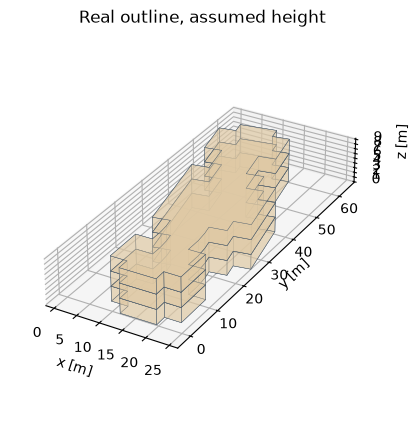

<function demo.support.common.preview(value, title='Resolved geometry', interactive=True, figsize=(9, 5))>

,field,value
0,synthetic_reference_area_m2,600.0000000000001
1,synthetic_reference_perimeter_m,113.13708498984761
2,real_conditioned_volume_m3,7530.662488487527


,field,value
0,synthetic_reference_area_m2,600.0000000000001
1,synthetic_reference_perimeter_m,113.13708498984761
2,real_conditioned_volume_m3,7530.662488487527


In [4]:
assert accepted, "No accepted sample; inspect preparation decisions"
g=accepted[0]
preview(g,"Real outline, assumed height")
display(preview)
assert len(g.footprints)==len(g.parts)

# Separate synthetic reference: scaled_to_area enables equal-area shape comparisons.
# This L-shape neither replaces nor approximates the real footprint above.
reference=Footprint.l_shape(30,30,15,15).scaled_to_area(600)
assert np.isclose(reference.area_m2,600)
table({"synthetic_reference_area_m2":reference.area_m2,
       "synthetic_reference_perimeter_m":reference.perimeter_m,
       "real_conditioned_volume_m3":g.conditioned_volume_m3})

## Interpretation and next experiment

Preserve source IDs and rejection counts. Scaling synthetic forms to a common area is useful for controlled sensitivity; do not silently rescale measured footprint geometry.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.